In [25]:
import logging
import os

# Create a folder to store log files
os.makedirs("logs", exist_ok=True)

# Configure logging
logging.basicConfig(
    filename="logs/rossmann_eda.log",
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    force=True
)

logger = logging.getLogger("rossmann_eda")

logger.info("Rossmann Store Sales EDA started.")

print("Logging setup completed successfully!")

Logging setup completed successfully!


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("/content/train_preprocessed.csv", low_memory=False)

print("Shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

Shape: (1017209, 32)
Date range: 2013-01-01 to 2015-07-31


* Univariate Analysis

SALES SUMMARY


,Sales
count,1.017209e+06
mean,5.773819e+03
std,3.849926e+03
min,0.000000e+00
25%,3.727000e+03
50%,5.744000e+03
75%,7.856000e+03
max,4.155100e+04


Skewness: 0.641
Kurtosis: 1.778
Zero-sales records: 172871
Zero-sales percentage: 16.99 %


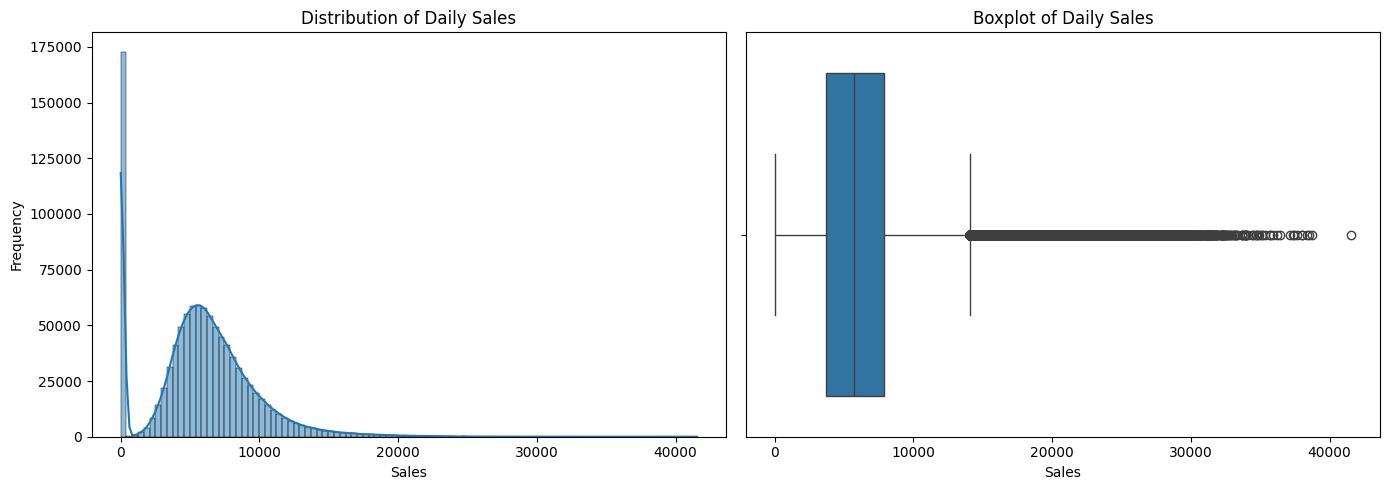

In [3]:

# Summary statistics
print("SALES SUMMARY")
display(df["Sales"].describe())

print("Skewness:", round(df["Sales"].skew(), 3))
print("Kurtosis:", round(df["Sales"].kurtosis(), 3))
print("Zero-sales records:", (df["Sales"] == 0).sum())
print("Zero-sales percentage:",
      round((df["Sales"] == 0).mean() * 100, 2), "%")

# Histogram and boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Sales"], bins=100, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Daily Sales")
axes[0].set_xlabel("Sales")
axes[0].set_ylabel("Frequency")

sns.boxplot(x=df["Sales"], ax=axes[1])
axes[1].set_title("Boxplot of Daily Sales")
axes[1].set_xlabel("Sales")

plt.tight_layout()
plt.show()


### Univariate Analysis: Sales

The Sales distribution is positively skewed, with a mean of 5,773.82 and a median of 5,744. The histogram shows a large concentration of zero-sales observations, a main peak in the mid-thousands, and a long right tail. The boxplot identifies numerous high-sales observations beyond the upper whisker, which should be investigated rather than automatically removed.

There are 172,871 zero-sales records, representing 16.99% of the dataset. These records require further investigation to determine their relationship with store closures. A log transformation may be worth testing, but the original Sales variable will be preserved during EDA.


Sales = 0 by Open status:


Sales is zero,False,True,All
Open,,,
0,0,172817,172817
1,844338,54,844392
All,844338,172871,1017209



Percentage of zero sales within each Open group:


,ZeroSales
Open,
0,100.00
1,0.01



CUSTOMERS SUMMARY


,Customers
count,1.017209e+06
mean,6.331459e+02
std,4.644117e+02
min,0.000000e+00
25%,4.050000e+02
50%,6.090000e+02
75%,8.370000e+02
max,7.388000e+03


Customers skewness: 1.599
Zero-customer records: 172869


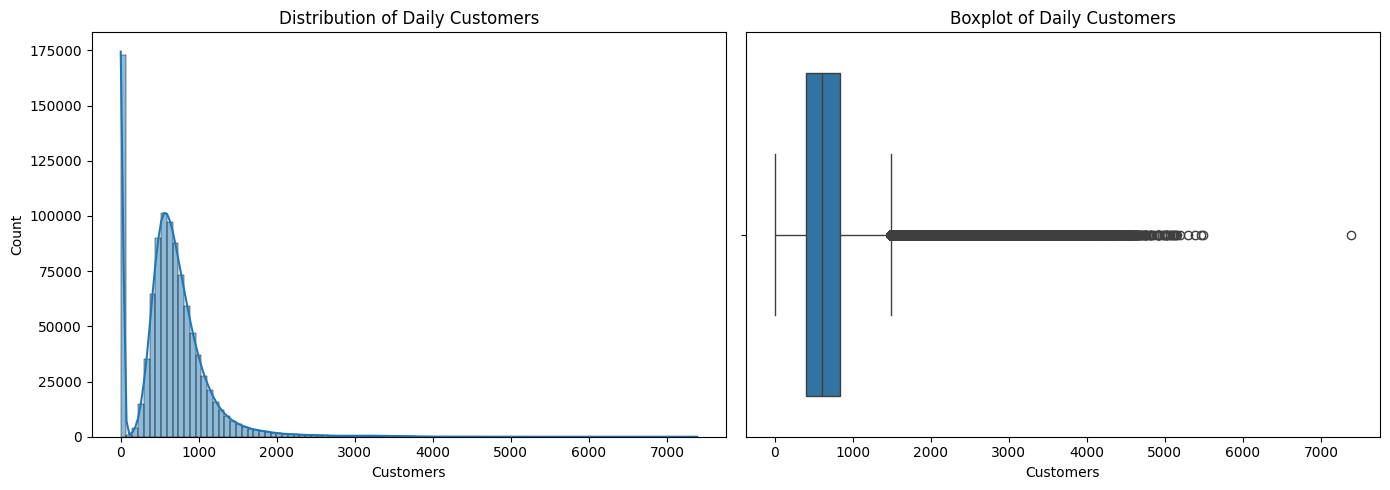

In [4]:

# Compare zero sales with store opening status
print("Sales = 0 by Open status:")
display(pd.crosstab(
    df["Open"],
    df["Sales"].eq(0),
    rownames=["Open"],
    colnames=["Sales is zero"],
    margins=True
))

print("\nPercentage of zero sales within each Open group:")
display(
    df.assign(ZeroSales=df["Sales"].eq(0))
      .groupby("Open", dropna=False)["ZeroSales"]
      .mean()
      .mul(100)
      .round(2)
)

# Customers univariate analysis
print("\nCUSTOMERS SUMMARY")
display(df["Customers"].describe())

print("Customers skewness:", round(df["Customers"].skew(), 3))
print("Zero-customer records:", (df["Customers"] == 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Customers"], bins=100, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Daily Customers")
axes[0].set_xlabel("Customers")

sns.boxplot(x=df["Customers"], ax=axes[1])
axes[1].set_title("Boxplot of Daily Customers")
axes[1].set_xlabel("Customers")

plt.tight_layout()
plt.show()


### Univariate Analysis: Customers

The Customers distribution is positively skewed, with a mean of 633.15 and a median of 609. The histogram shows a concentration of daily customer counts in the hundreds, together with a long right tail. The boxplot reveals numerous high-count observations that should be investigated rather than automatically removed.

There are 172,869 records with zero customers. Since zero customers are closely associated with store closures, subsequent sales and customer analyses should distinguish open and closed stores. The original Customers values will be preserved during EDA.


COMPETITION DISTANCE SUMMARY


,CompetitionDistance
count,1.017209e+06
mean,5.422034e+03
std,7.706913e+03
min,2.000000e+01
25%,7.100000e+02
50%,2.330000e+03
75%,6.880000e+03
max,7.586000e+04


CompetitionDistance skewness: 2.933


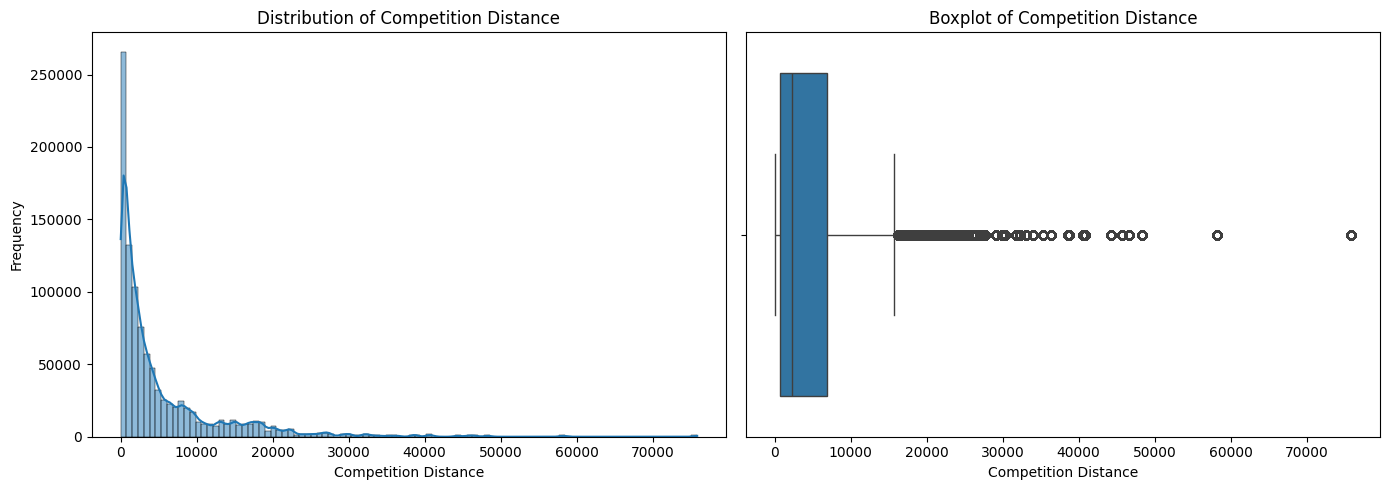

In [5]:

# Summary statistics
print("COMPETITION DISTANCE SUMMARY")
display(df["CompetitionDistance"].describe())

print(
    "CompetitionDistance skewness:",
    round(df["CompetitionDistance"].skew(), 3)
)

# Histogram and boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="CompetitionDistance",
    bins=100,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Competition Distance")
axes[0].set_xlabel("Competition Distance")
axes[0].set_ylabel("Frequency")

sns.boxplot(
    x=df["CompetitionDistance"],
    ax=axes[1]
)
axes[1].set_title("Boxplot of Competition Distance")
axes[1].set_xlabel("Competition Distance")

plt.tight_layout()
plt.show()


### Univariate Analysis: CompetitionDistance

CompetitionDistance is strongly positively skewed, with a mean of approximately 5,422 and a median of 2,330. The histogram shows that observations are concentrated at smaller distances, while a long right tail extends to 75,860. The boxplot identifies several extreme values that should be investigated but not automatically removed.

Because CompetitionDistance is a store-level characteristic repeated across daily records, its store-level distribution should also be examined using one record per store. A logarithmic transformation may be considered later if it benefits the selected model.


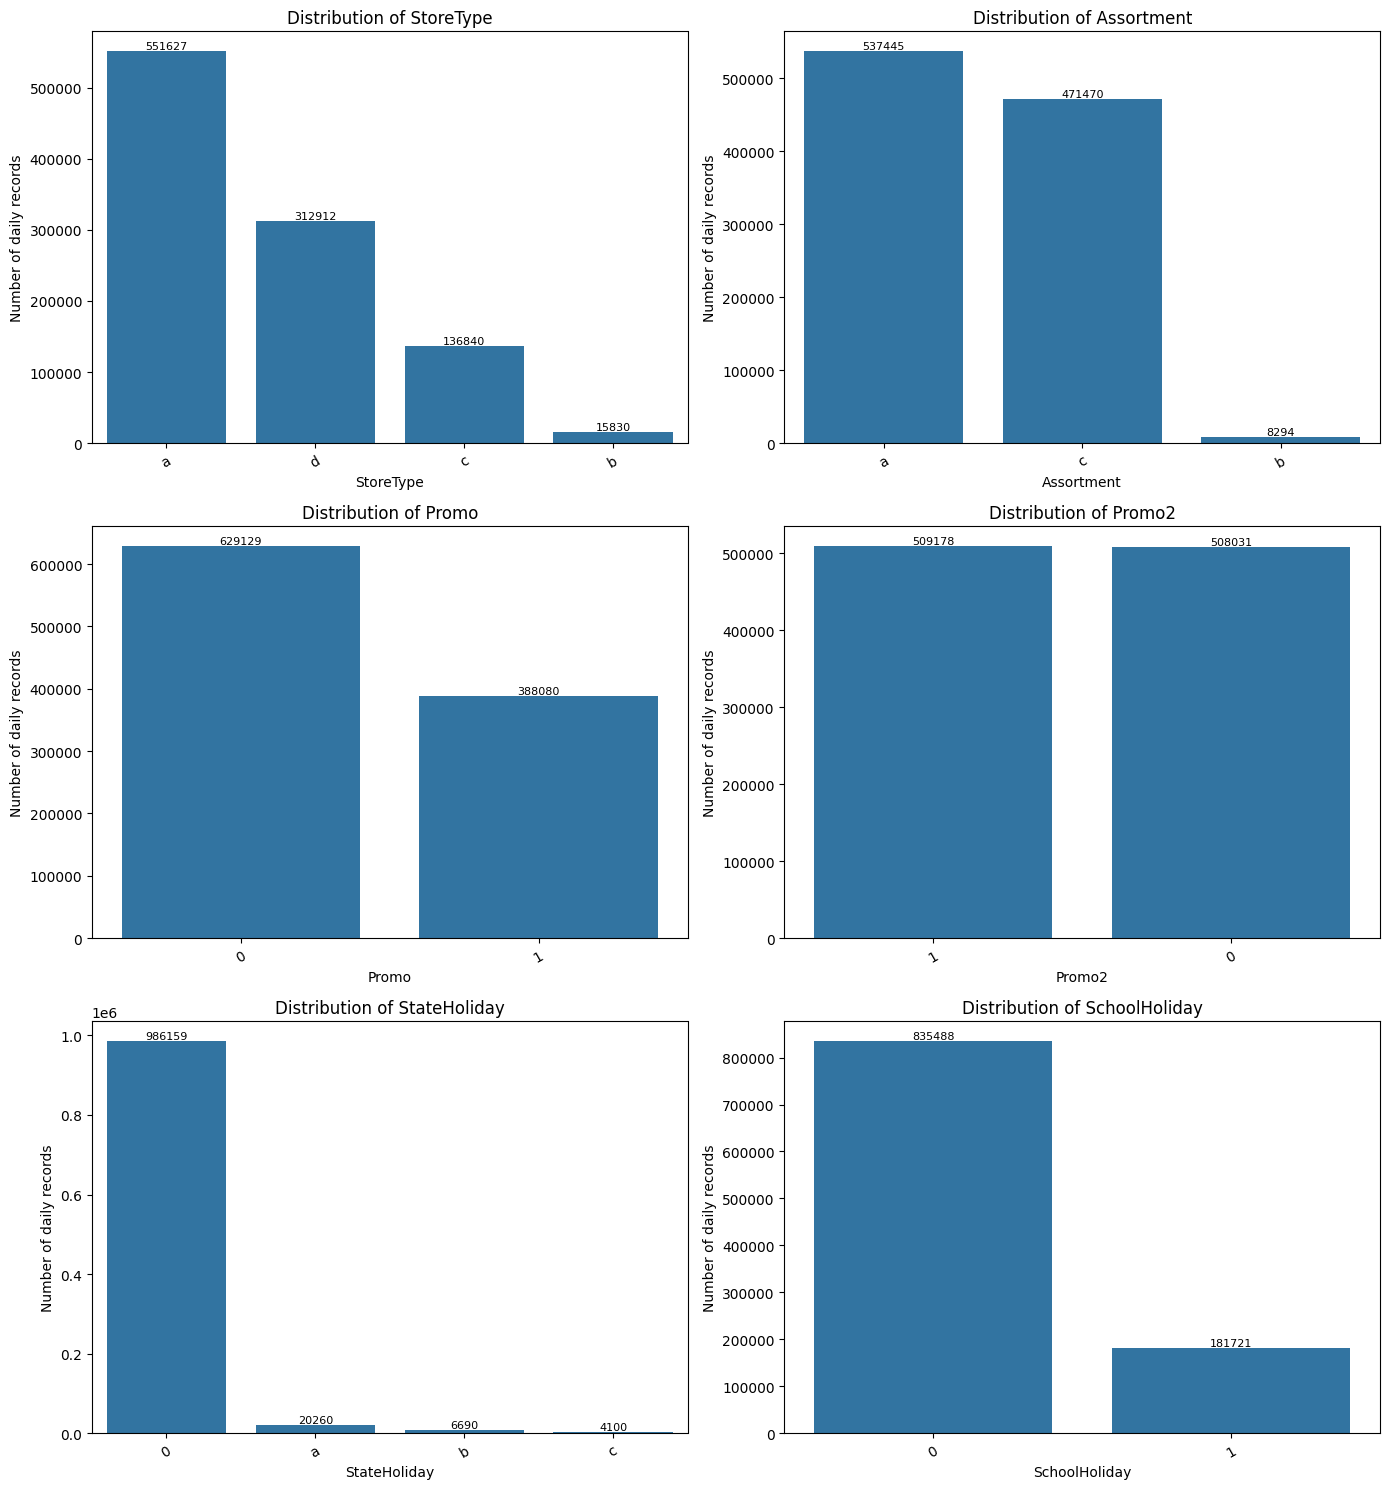


StoreType — proportions (%)


,Percentage
StoreType,
a,54.23
d,30.76
c,13.45
b,1.56



Assortment — proportions (%)


,Percentage
Assortment,
a,52.84
c,46.35
b,0.82



Promo — proportions (%)


,Percentage
Promo,
0,61.85
1,38.15


... (2 outputs left out)


StateHoliday — proportions (%)


,Percentage
StateHoliday,
0,96.95
a,1.99
b,0.66
c,0.4



SchoolHoliday — proportions (%)


,Percentage
SchoolHoliday,
0,82.14
1,17.86


In [6]:

# Categorical variables for univariate analysis
categorical_cols = [
    "StoreType",
    "Assortment",
    "Promo",
    "Promo2",
    "StateHoliday",
    "SchoolHoliday"
]

# Frequency tables and count plots
fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for ax, col in zip(axes, categorical_cols):
    counts = df[col].astype("string").fillna("Missing").value_counts()

    sns.barplot(
        x=counts.index.astype(str),
        y=counts.values,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of daily records")
    ax.tick_params(axis="x", rotation=30)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", fontsize=8)

plt.tight_layout()
plt.show()

# Print category proportions
for col in categorical_cols:
    print(f"\n{col} — proportions (%)")
    display(
        df[col]
        .astype("string")
        .fillna("Missing")
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .rename("Percentage")
        .to_frame()
    )


### Univariate Analysis: Categorical Variables

The categorical distributions reveal that StoreType A is the most common store type (54.23%), while StoreType B represents only 1.56% of daily records. Assortment A is the most prevalent assortment category (52.84%), followed by C (46.35%); assortment B accounts for just 0.82%.

Approximately 38.15% of daily records have an active Promo, while Promo2 participation is almost evenly distributed between participating and non-participating stores. Most observations occur on non-state-holiday days (96.95%), and 17.86% of records correspond to school holidays.

These distributions identify important variables for further investigation. In particular, subsequent analyses should examine sales differences across store types, assortment categories, promotional conditions, and holiday periods. The relatively small representation of some categories should be considered when interpreting group comparisons.

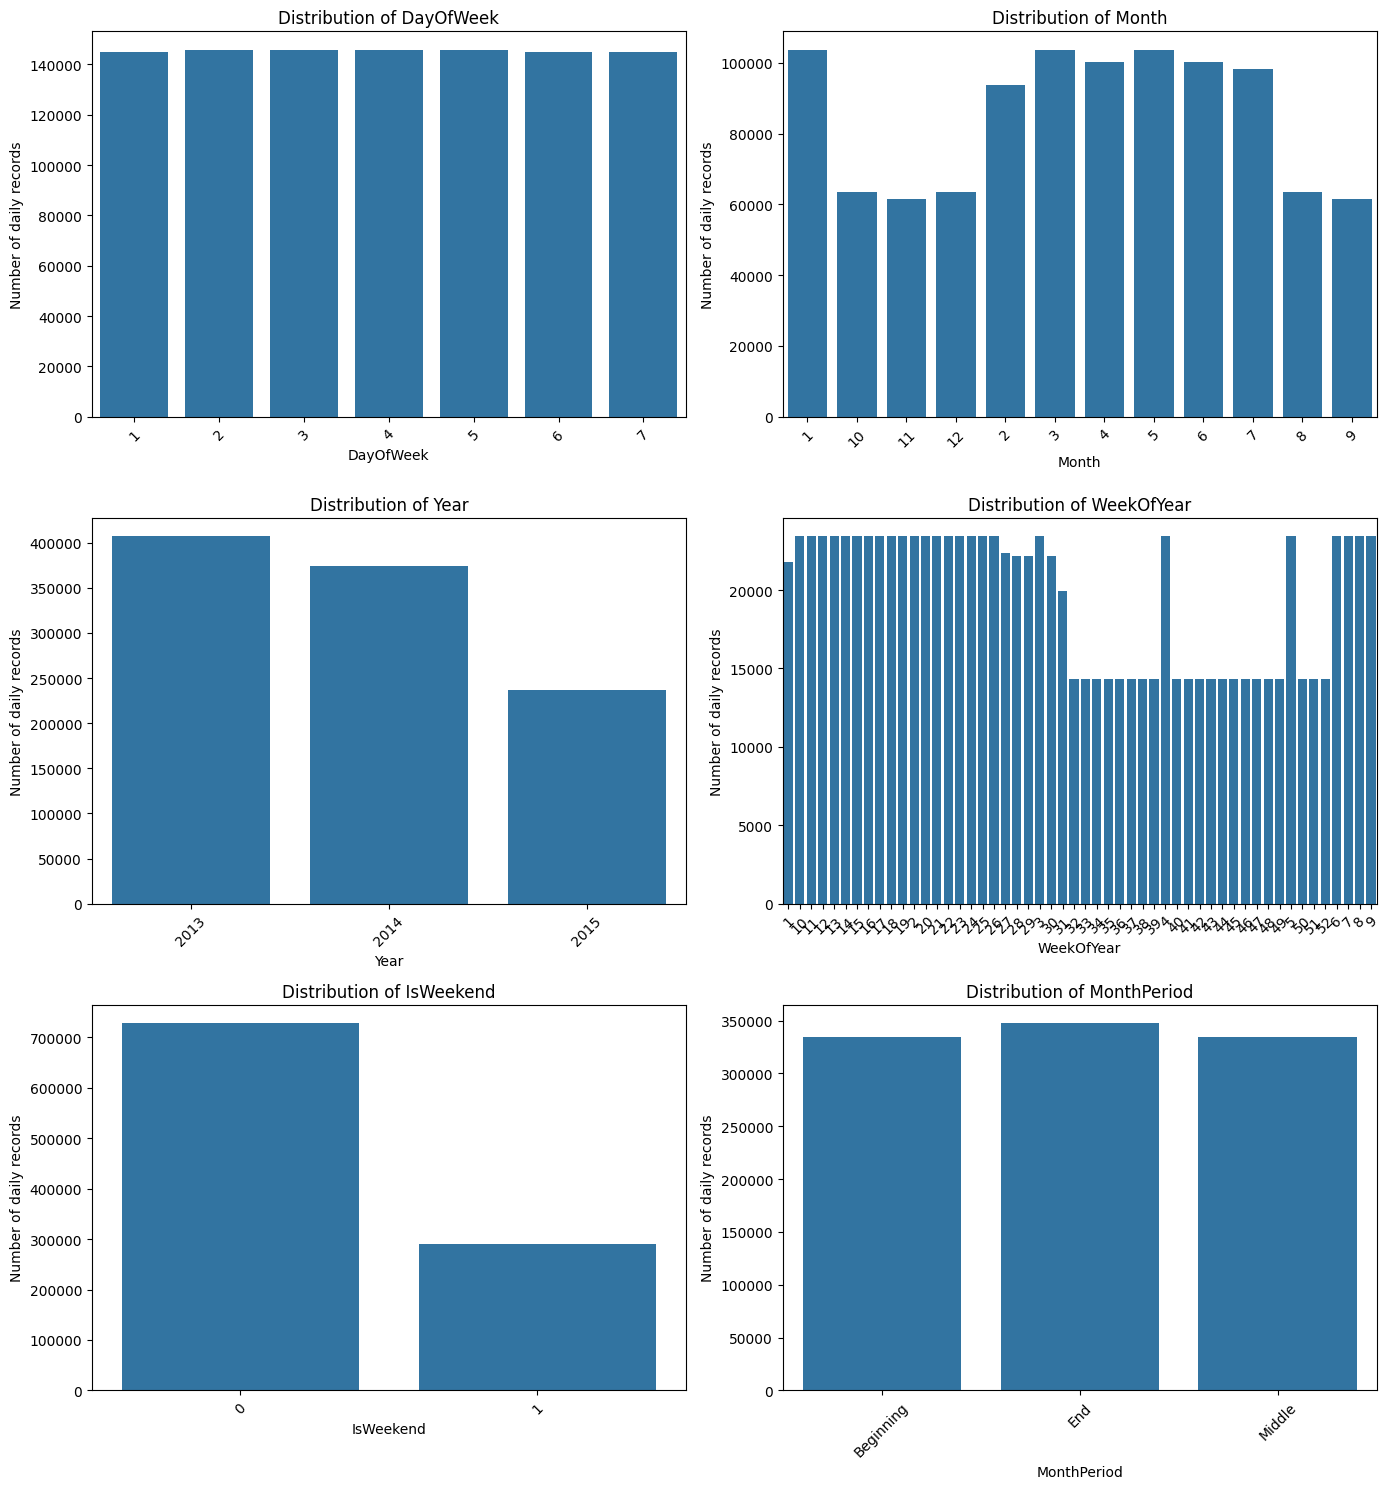

In [7]:
# Date-related variables
date_cols = [
    "DayOfWeek",
    "Month",
    "Year",
    "WeekOfYear",
    "IsWeekend",
    "MonthPeriod"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for ax, col in zip(axes, date_cols):

    counts = (
        df[col]
        .astype("string")
        .fillna("Missing")
        .value_counts()
        .sort_index()
    )

    sns.barplot(
        x=counts.index.astype(str),
        y=counts.values,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of daily records")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Univariate Analysis: Date-Related Features

The DayOfWeek distribution is approximately balanced across the seven weekdays. The monthly distribution varies, partly because the dataset covers incomplete calendar years. The Year distribution reflects the available observation periods, with 2013 and 2015 covering only part of the full three-year period.

The WeekOfYear plot reveals variation in record counts, although the category ordering should be corrected to numerical order for clearer interpretation. The IsWeekend feature contains more weekday records than weekend records, while MonthPeriod has relatively similar counts across its three categories.

These findings suggest that time-related variables should be investigated further using average sales and customer counts rather than record frequencies alone. Year-to-year comparisons should use comparable date ranges to avoid misleading conclusions.

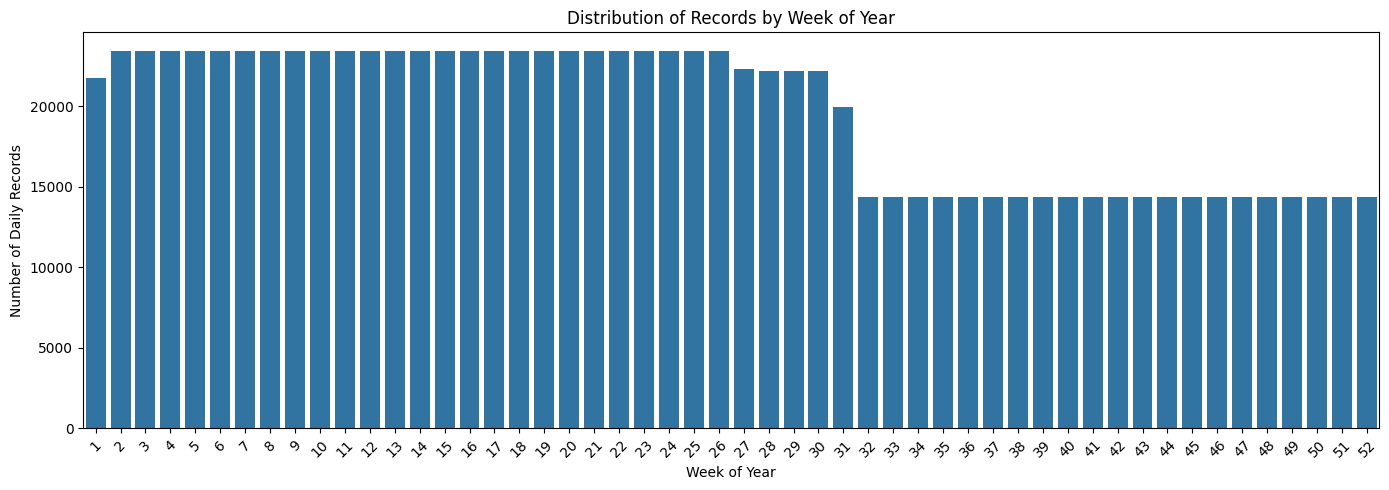

In [8]:
# Correctly order WeekOfYear numerically
weekly_counts = (
    df["WeekOfYear"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(14, 5))

sns.barplot(
    x=weekly_counts.index,
    y=weekly_counts.values
)

plt.title("Distribution of Records by Week of Year")
plt.xlabel("Week of Year")
plt.ylabel("Number of Daily Records")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Univariate Analysis: WeekOfYear

The distribution of daily records is relatively stable across the earlier weeks of the year, with lower counts in the later weeks. This pattern is largely explained by the dataset's observation period, which ends on July 31, 2015. Consequently, the later weeks contain records from fewer years. These differences should not be interpreted as changes in sales or store performance without further analysis.

In [9]:
# Store-level distributions
store_level = df.drop_duplicates(subset="Store")

print("Number of unique stores:", store_level["Store"].nunique())

for col in ["StoreType", "Assortment"]:
    print(f"\nUnique store counts by {col}:")
    display(
        store_level[col]
        .value_counts()
        .rename("Number of stores")
        .to_frame()
    )

# CompetitionDistance: one observation per store
print("\nCompetitionDistance summary at store level:")
display(store_level["CompetitionDistance"].describe())

Number of unique stores: 1115

Unique store counts by StoreType:


,Number of stores
StoreType,
a,602
d,348
c,148
b,17



Unique store counts by Assortment:


,Number of stores
Assortment,
a,593
c,513
b,9



CompetitionDistance summary at store level:


,CompetitionDistance
count,1115.000000
mean,5396.627803
std,7654.508236
min,20.000000
25%,720.000000
50%,2330.000000
75%,6875.000000
max,75860.000000


### Store-Level Univariate Analysis

The dataset contains 1,115 unique stores. StoreType A is the most common category, representing approximately 53.99% of stores, followed by StoreType D at 31.21%, StoreType C at 13.27%, and StoreType B at 1.52%.

For assortment, category A represents 53.18% of stores, category C represents 46.01%, and category B represents only 0.81%.

CompetitionDistance has a mean of approximately 5,396.63 and a median of 2,330. Its maximum value is 75,860, and the mean being substantially higher than the median indicates a positively skewed distribution.

These results describe the store-level structure of the dataset. The small number of stores in StoreType B and Assortment B should be considered when comparing sales across categories.

* Bivariate Analysis

Correlation (all records): 0.8947
Correlation (open stores only): 0.8236


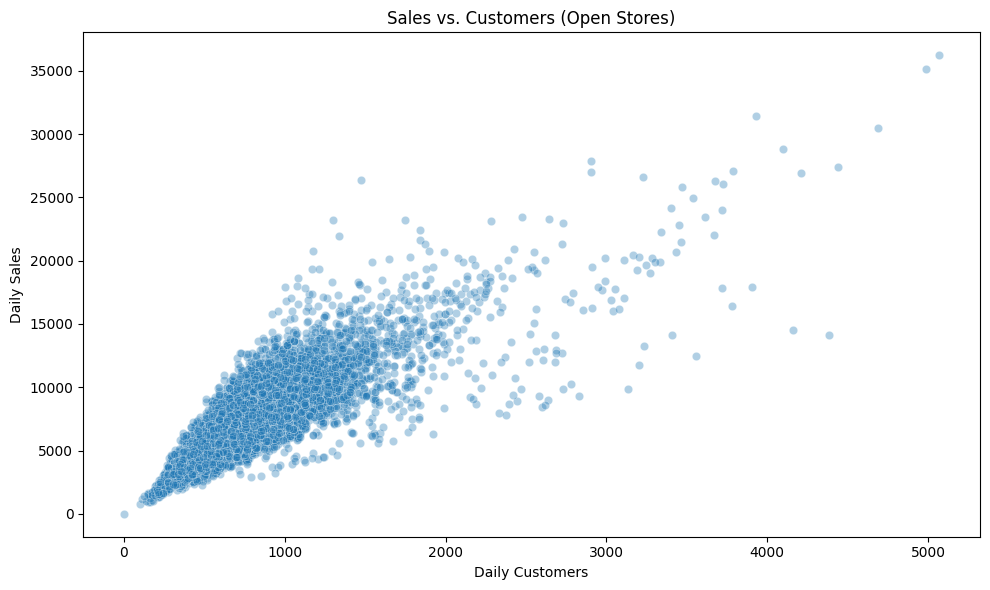

In [10]:
# Bivariate Analysis 1: Sales vs. Customers

# Keep records with valid Sales and Customers
sales_customers = df.dropna(subset=["Sales", "Customers"]).copy()

# Correlation across all records
corr_all = sales_customers["Sales"].corr(
    sales_customers["Customers"]
)

# Correlation for open stores only
open_stores = sales_customers[
    sales_customers["Open"] == 1
].copy()

corr_open = open_stores["Sales"].corr(
    open_stores["Customers"]
)

print(f"Correlation (all records): {corr_all:.4f}")
print(f"Correlation (open stores only): {corr_open:.4f}")

# Scatter plot for open stores
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=open_stores.sample(
        n=min(10000, len(open_stores)),
        random_state=42
    ),
    x="Customers",
    y="Sales",
    alpha=0.35
)

plt.title("Sales vs. Customers (Open Stores)")
plt.xlabel("Daily Customers")
plt.ylabel("Daily Sales")
plt.tight_layout()
plt.show()

### Bivariate Analysis: Sales vs. Customers

Sales and Customers exhibit a strong positive correlation. The Pearson correlation coefficient is 0.8947 when all records are included and 0.8236 when the analysis is restricted to open stores.

The scatter plot shows that daily sales generally increase with customer numbers, although considerable variation remains. The higher correlation across all records is partly associated with closed stores, which typically have zero sales and zero customers.

This analysis indicates that customer traffic is strongly associated with sales. However, Customers is not available in the competition's test dataset, so it must not be used as a predictor when building the final sales forecasting model for that test set.

Sales summary by promotional status (open stores only):


,count,mean,median,std
No Promotion (0),467496,5929.41,5459.0,2629.65
Promotion (1),376896,8228.28,7649.0,3175.76


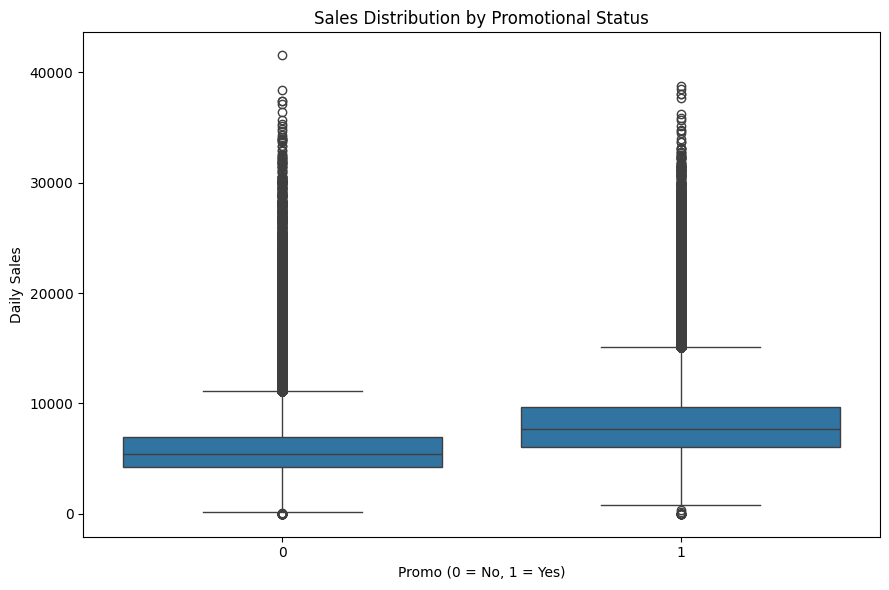

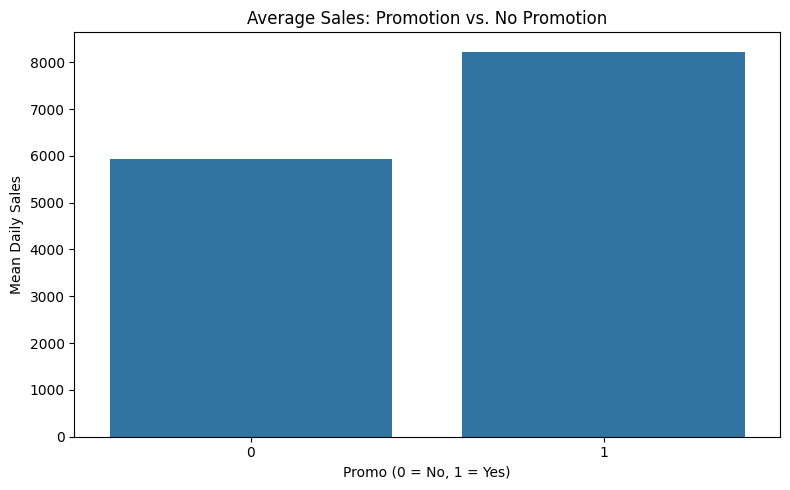

In [11]:
# Bivariate Analysis 2: Sales vs Promo

# Analyze open stores only
promo_df = df[
    (df["Open"] == 1) &
    (df["Sales"].notna()) &
    (df["Promo"].notna())
].copy()

# Summary statistics
promo_summary = (
    promo_df.groupby("Promo")["Sales"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

promo_summary.index = [
    "No Promotion (0)" if x == 0 else "Promotion (1)"
    for x in promo_summary.index
]

print("Sales summary by promotional status (open stores only):")
display(promo_summary)

# Boxplot
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=promo_df,
    x="Promo",
    y="Sales"
)

plt.title("Sales Distribution by Promotional Status")
plt.xlabel("Promo (0 = No, 1 = Yes)")
plt.ylabel("Daily Sales")

plt.tight_layout()
plt.show()

# Mean sales comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=promo_df,
    x="Promo",
    y="Sales",
    errorbar=None
)

plt.title("Average Sales: Promotion vs. No Promotion")
plt.xlabel("Promo (0 = No, 1 = Yes)")
plt.ylabel("Mean Daily Sales")

plt.tight_layout()
plt.show()

### Bivariate Analysis: Sales vs. Promo

The analysis compares sales on promotional and non-promotional days, considering open stores only. Mean daily sales were 5,929.41 without promotions and 8,228.28 with promotions, representing an increase of approximately 38.8%. Median sales also increased from 5,459 to 7,649.

The boxplot indicates that sales distributions differ between the two groups, with promotional days showing higher central values and greater variability. Both groups contain high-sales outliers that should not automatically be classified as errors.

Overall, promotions are associated with higher daily sales in this dataset. However, this descriptive comparison does not establish causation because sales may also depend on store characteristics, weekdays, seasonality, and other factors.

Sales summary by weekday (open stores only):


,count,mean,median,std
DayOfWeek,,,,
1,137560,8216.07,7539.0,3691.77
2,143961,7088.11,6502.0,3066.24
3,141936,6728.12,6210.0,2781.78
4,134644,6767.31,6246.0,2764.55
5,138640,7072.68,6580.0,2764.92
6,144058,5874.84,5425.0,2852.73
7,3593,8224.72,6876.0,6235.15


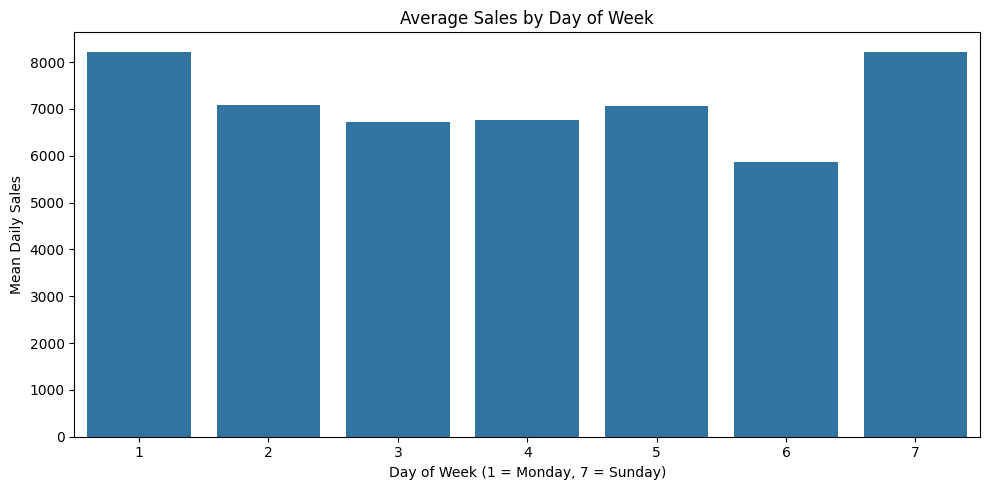

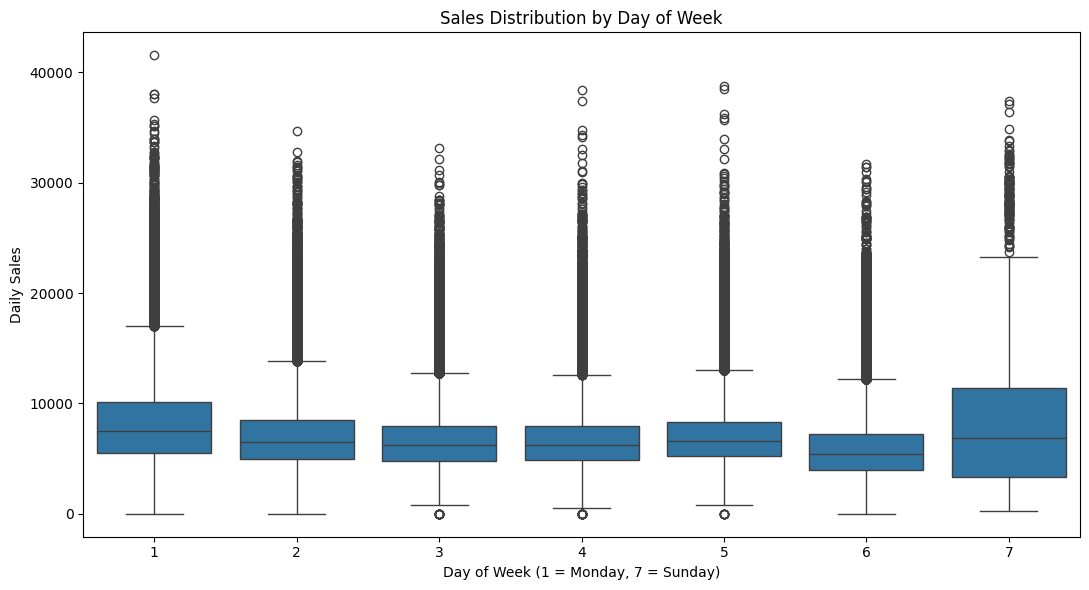

In [12]:
# Bivariate Analysis 3: Sales vs. DayOfWeek

# Filter to open stores with valid Sales and DayOfWeek
weekday_df = df[
    (df["Open"] == 1) &
    df["Sales"].notna() &
    df["DayOfWeek"].notna()
].copy()

# Summary statistics by weekday
weekday_summary = (
    weekday_df.groupby("DayOfWeek")["Sales"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

print("Sales summary by weekday (open stores only):")
display(weekday_summary)

# Mean sales by weekday
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_df,
    x="DayOfWeek",
    y="Sales",
    errorbar=None
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week (1 = Monday, 7 = Sunday)")
plt.ylabel("Mean Daily Sales")

plt.tight_layout()
plt.show()

# Sales distribution by weekday
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=weekday_df,
    x="DayOfWeek",
    y="Sales"
)

plt.title("Sales Distribution by Day of Week")
plt.xlabel("Day of Week (1 = Monday, 7 = Sunday)")
plt.ylabel("Daily Sales")

plt.tight_layout()
plt.show()

### Bivariate Analysis: Sales vs. Day of Week

The relationship between sales and the day of the week was analyzed using open-store records.

Monday recorded the highest mean sales among weekdays, at 8,216.07, while Wednesday recorded the lowest weekday mean, at 6,728.12. Sales declined on Saturday, which had the lowest overall mean of 5,874.84.

Sunday showed the highest mean sales at 8,224.72. However, only 3,593 open-store observations were available for Sunday, considerably fewer than for the other days. Its high standard deviation of 6,235.15 also indicates substantial variability. Therefore, Sunday results should be interpreted cautiously.

The boxplot reveals differences in the distributions of daily sales and high-sales outliers across weekdays. Overall, day of the week appears to be an important variable for understanding sales patterns. Store opening practices and differences in the stores operating on Sundays should be considered when interpreting these results.

Sales summary by StoreType (open stores only):


,count,mean,median,std
StoreType,,,,
b,15563,10231.41,9130.0,5157.19
c,112978,6932.51,6407.0,2897.56
a,457077,6925.17,6285.0,3277.79
d,258774,6822.14,6395.0,2556.58


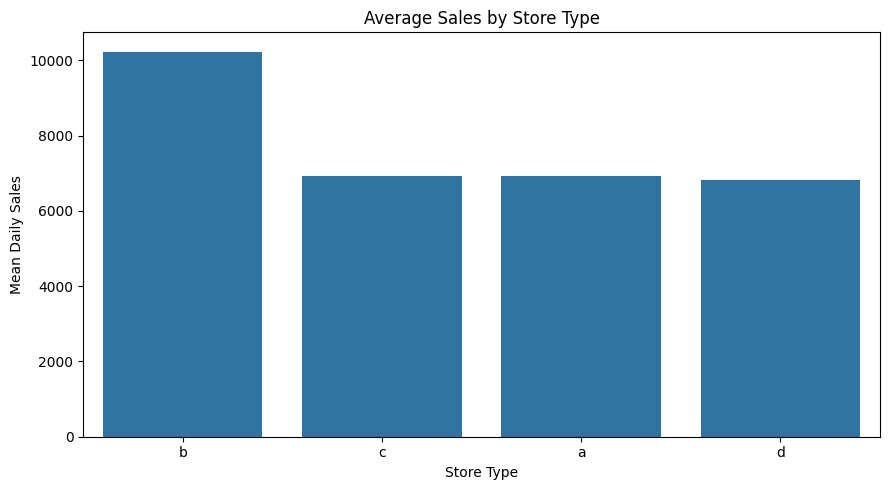

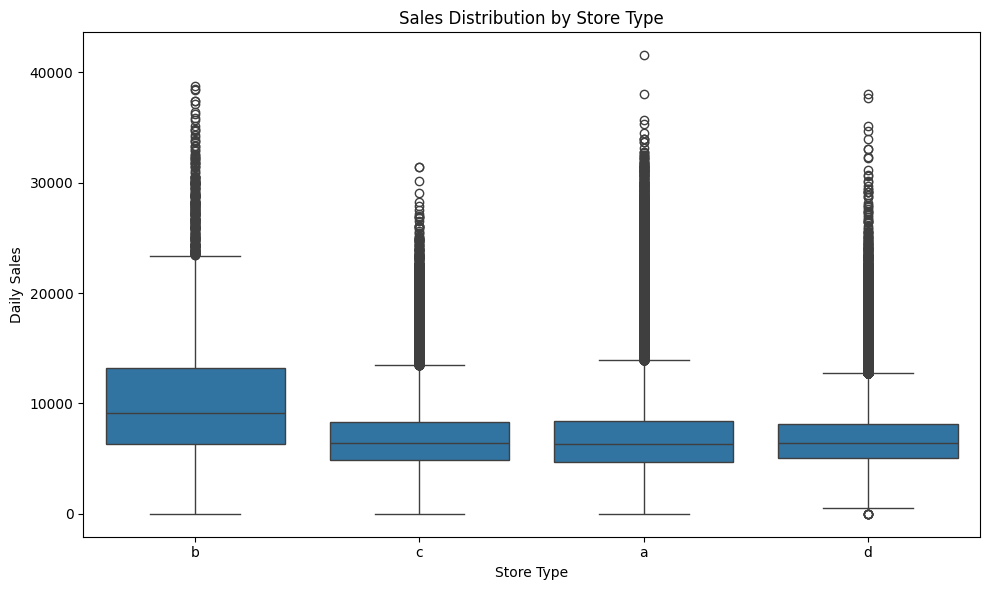

In [13]:
# Bivariate Analysis 4: Sales vs. StoreType

# Keep open stores with valid sales and store type
storetype_df = df[
    (df["Open"] == 1) &
    df["Sales"].notna() &
    df["StoreType"].notna()
].copy()

# Summary statistics
storetype_summary = (
    storetype_df.groupby("StoreType")["Sales"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
    .sort_values("mean", ascending=False)
)

print("Sales summary by StoreType (open stores only):")
display(storetype_summary)

# Mean sales by store type
plt.figure(figsize=(9, 5))

sns.barplot(
    data=storetype_df,
    x="StoreType",
    y="Sales",
    errorbar=None,
    order=storetype_summary.index
)

plt.title("Average Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Mean Daily Sales")

plt.tight_layout()
plt.show()

# Distribution of sales by store type
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=storetype_df,
    x="StoreType",
    y="Sales",
    order=storetype_summary.index
)

plt.title("Sales Distribution by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Daily Sales")

plt.tight_layout()
plt.show()

### Bivariate Analysis: Sales vs. StoreType

The analysis compares daily sales across the four store types using open-store records.

Store Type B recorded the highest mean sales of 10,231.41 and the highest median sales of 9,130. Its standard deviation of 5,157.19 also indicates greater variability in sales. However, Type B has considerably fewer observations than the other types, so this result should be interpreted cautiously.

Store Types A, C, and D showed relatively similar mean sales of 6,925.17, 6,932.51, and 6,822.14, respectively. The boxplot shows differences in the distributions and variability of sales, with high-sales outliers appearing across all four types.

Overall, store type appears to be associated with daily sales. Further analysis controlling for factors such as promotions, weekdays, and individual store characteristics could help clarify these differences.

Sales summary by Assortment (open stores only):


,count,mean,median,std
Assortment,,,,
b,8212,8639.35,8081.0,3806.01
c,391271,7300.53,6675.0,3184.14
a,444909,6621.02,6082.0,2972.50


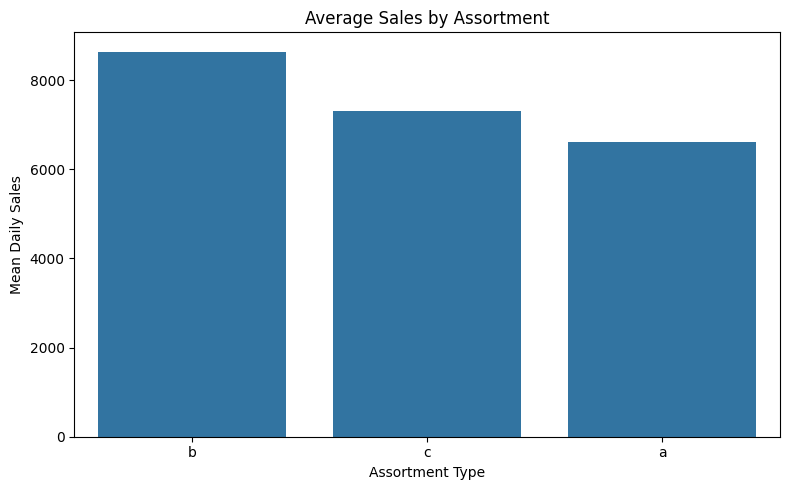

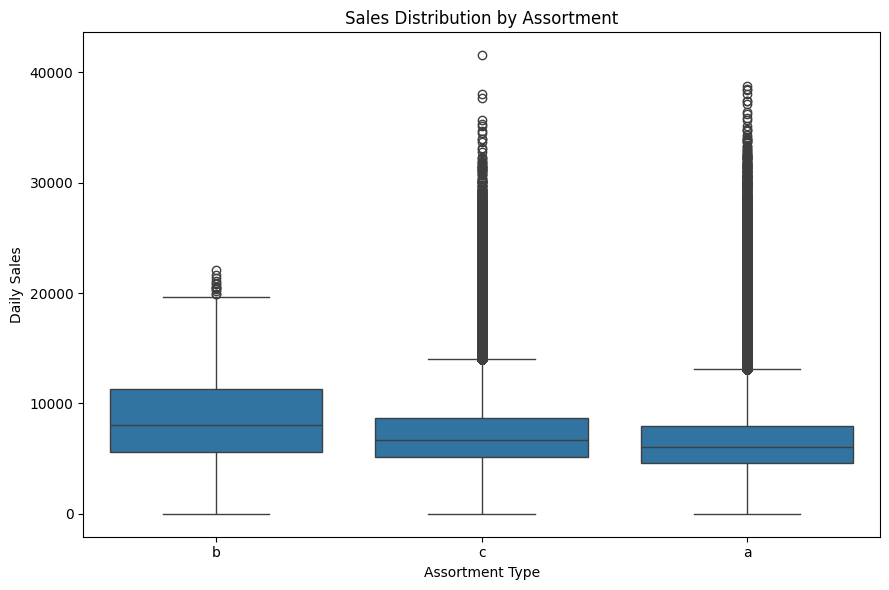

In [14]:
# Bivariate Analysis 5: Sales vs. Assortment

# Keep open stores with valid Sales and Assortment
assortment_df = df[
    (df["Open"] == 1) &
    df["Sales"].notna() &
    df["Assortment"].notna()
].copy()

# Summary statistics
assortment_summary = (
    assortment_df.groupby("Assortment")["Sales"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
    .sort_values("mean", ascending=False)
)

print("Sales summary by Assortment (open stores only):")
display(assortment_summary)

# Mean sales by assortment
plt.figure(figsize=(8, 5))

sns.barplot(
    data=assortment_df,
    x="Assortment",
    y="Sales",
    errorbar=None,
    order=assortment_summary.index
)

plt.title("Average Sales by Assortment")
plt.xlabel("Assortment Type")
plt.ylabel("Mean Daily Sales")

plt.tight_layout()
plt.show()

# Sales distribution by assortment
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=assortment_df,
    x="Assortment",
    y="Sales",
    order=assortment_summary.index
)

plt.title("Sales Distribution by Assortment")
plt.xlabel("Assortment Type")
plt.ylabel("Daily Sales")

plt.tight_layout()
plt.show()

### Bivariate Analysis: Sales vs. Assortment

The analysis compares daily sales across assortment categories A, B, and C, using open-store records.

Assortment B recorded the highest mean daily sales of 8,639.35 and the highest median sales of 8,081. Assortment C followed, with mean sales of 7,300.53, while Assortment A had the lowest mean sales of 6,621.02.

Assortment B also exhibited the greatest variability, with a standard deviation of 3,806.01. However, it had only 8,212 observations, substantially fewer than Assortments A and C. Its results should therefore be interpreted cautiously.

The boxplot shows differences in the central sales distributions and the presence of high-sales outliers across all three categories.

Overall, assortment category appears to be associated with sales. Further analysis controlling for store type, promotions, and other variables would help determine whether these differences persist after accounting for other factors.

Sales summary by school-holiday status (open stores only):


,count,mean,median,std
No School Holiday (0),680935,6896.78,6326.0,3083.77
School Holiday (1),163457,7200.18,6562.0,3176.30


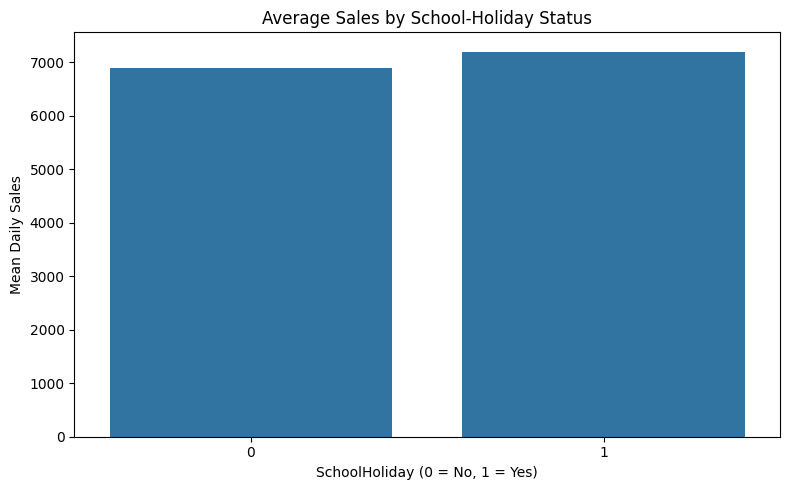

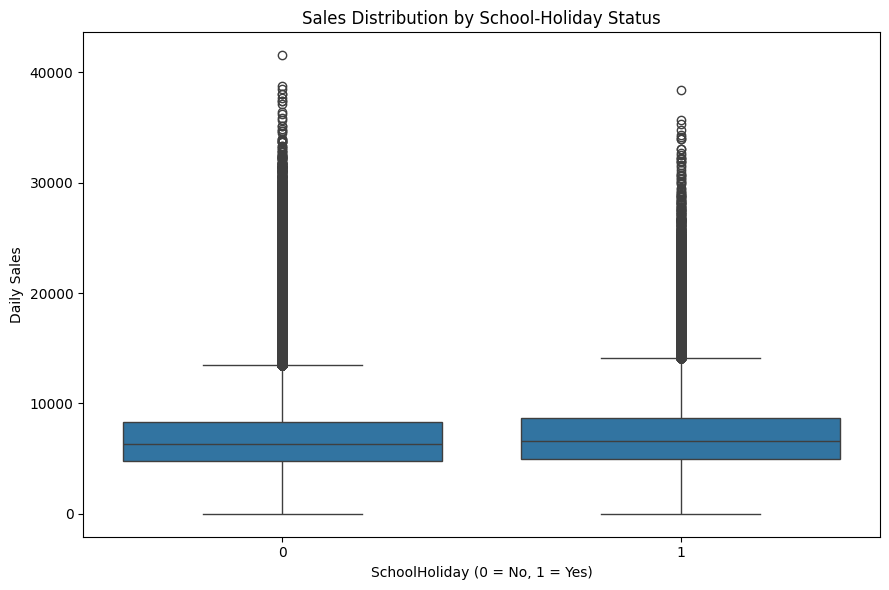

In [15]:
# Bivariate Analysis 6: Sales vs. SchoolHoliday

# Keep open stores with valid Sales and SchoolHoliday
holiday_df = df[
    (df["Open"] == 1) &
    df["Sales"].notna() &
    df["SchoolHoliday"].notna()
].copy()

# Summary statistics
holiday_summary = (
    holiday_df.groupby("SchoolHoliday")["Sales"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

holiday_summary.index = [
    "No School Holiday (0)" if x == 0
    else "School Holiday (1)"
    for x in holiday_summary.index
]

print("Sales summary by school-holiday status (open stores only):")
display(holiday_summary)

# Mean sales by school-holiday status
plt.figure(figsize=(8, 5))

sns.barplot(
    data=holiday_df,
    x="SchoolHoliday",
    y="Sales",
    errorbar=None
)

plt.title("Average Sales by School-Holiday Status")
plt.xlabel("SchoolHoliday (0 = No, 1 = Yes)")
plt.ylabel("Mean Daily Sales")

plt.tight_layout()
plt.show()

# Sales distribution
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=holiday_df,
    x="SchoolHoliday",
    y="Sales"
)

plt.title("Sales Distribution by School-Holiday Status")
plt.xlabel("SchoolHoliday (0 = No, 1 = Yes)")
plt.ylabel("Daily Sales")

plt.tight_layout()
plt.show()

### Bivariate Analysis: Sales vs. SchoolHoliday

The analysis compares daily sales during school holidays and non-school-holiday periods, considering open stores only.

Mean daily sales were 7,200.18 during school holidays and 6,896.78 during non-school-holiday periods, representing an increase of approximately 4.4%. Median sales were also higher during school holidays, increasing from 6,326 to 6,562.

The standard deviation was slightly higher during school holidays, indicating somewhat greater variability. However, the boxplot shows substantial overlap between the two sales distributions.

Overall, school-holiday status is associated with a modest difference in daily sales. Further analysis controlling for promotions, weekdays, seasonal patterns, and store characteristics would help determine whether this relationship persists after accounting for other factors.

Sales summary by StateHoliday (open stores only):


,count,mean,median,std
StateHoliday,,,,
b,145,9887.89,8423.0,7551.78
c,71,9743.75,8397.0,5980.86
a,694,8487.47,7556.0,5708.63
0,843482,6953.52,6368.0,3098.87


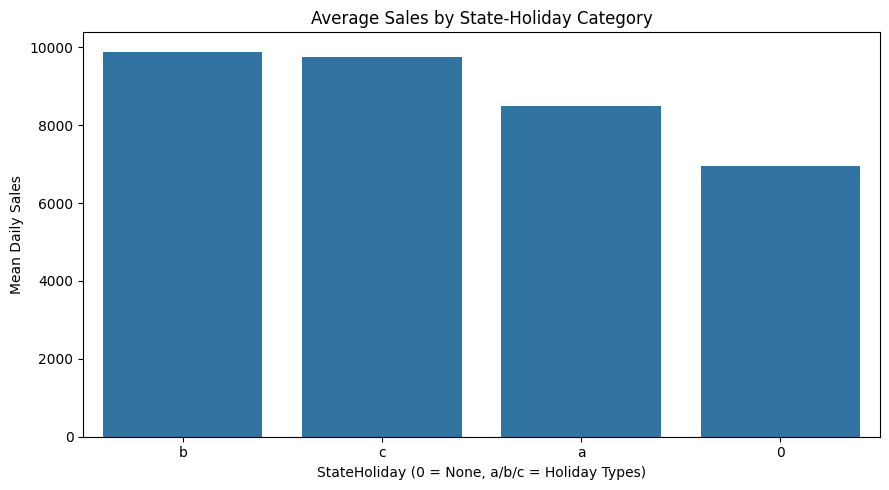

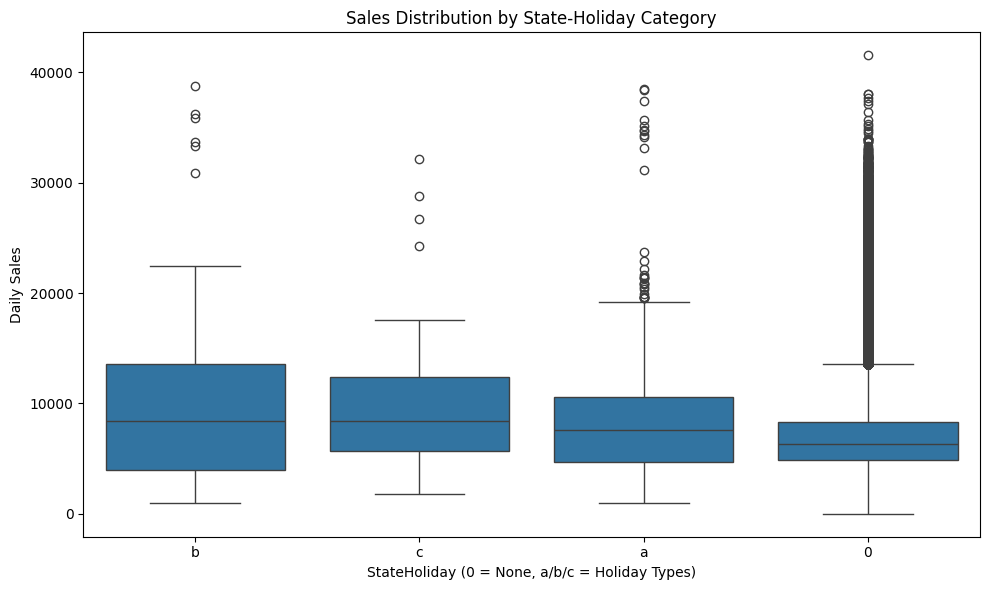

In [16]:
# Bivariate Analysis 7: Sales vs. StateHoliday

# Keep open stores with valid Sales and StateHoliday
stateholiday_df = df[
    (df["Open"] == 1) &
    df["Sales"].notna() &
    df["StateHoliday"].notna()
].copy()

# Normalize StateHoliday labels for consistent grouping
stateholiday_df["StateHoliday"] = (
    stateholiday_df["StateHoliday"]
    .astype(str)
    .str.strip()
)

# Summary statistics
stateholiday_summary = (
    stateholiday_df.groupby("StateHoliday")["Sales"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
    .sort_values("mean", ascending=False)
)

print("Sales summary by StateHoliday (open stores only):")
display(stateholiday_summary)

# Mean sales by state-holiday category
plt.figure(figsize=(9, 5))

sns.barplot(
    data=stateholiday_df,
    x="StateHoliday",
    y="Sales",
    errorbar=None,
    order=stateholiday_summary.index
)

plt.title("Average Sales by State-Holiday Category")
plt.xlabel("StateHoliday (0 = None, a/b/c = Holiday Types)")
plt.ylabel("Mean Daily Sales")

plt.tight_layout()
plt.show()

# Sales distribution by state-holiday category
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=stateholiday_df,
    x="StateHoliday",
    y="Sales",
    order=stateholiday_summary.index
)

plt.title("Sales Distribution by State-Holiday Category")
plt.xlabel("StateHoliday (0 = None, a/b/c = Holiday Types)")
plt.ylabel("Daily Sales")

plt.tight_layout()
plt.show()

### Bivariate Analysis: Sales vs. StateHoliday

The relationship between daily sales and state-holiday status was examined using open-store records.

Easter holidays (category b) had the highest mean sales at 9,887.89, followed by Christmas holidays (category c) at 9,743.75 and public holidays (category a) at 8,487.47. Mean sales on non-holiday days were 6,953.52.

Median sales followed a similar pattern, with values of 8,423 for Easter, 8,397 for Christmas, 7,556 for public holidays, and 6,368 for non-holiday days.

However, the holiday categories contained substantially fewer observations than the non-holiday category, particularly Christmas, which had only 71 open-store records. Holiday comparisons should therefore be interpreted cautiously. Sales variability was also higher in the holiday categories.

Overall, state-holiday status is associated with differences in observed daily sales. Further analysis should account for store characteristics, promotions, weekdays, and the limited number of observations for individual holiday categories.

Sales summary by month (open stores only):


,count,mean,median,std
Month,,,,
1,86343,6563.69,6062.0,2849.59
2,80243,6589.17,6078.0,2870.96
3,85980,6976.41,6385.0,3123.92
4,81731,7046.23,6431.0,3138.85
5,80103,7106.45,6592.0,3008.18
6,82576,7000.98,6365.0,3145.07
7,85587,6952.68,6407.0,3004.09
8,54413,6648.98,6124.0,2901.80
9,52330,6546.34,5999.0,2890.46


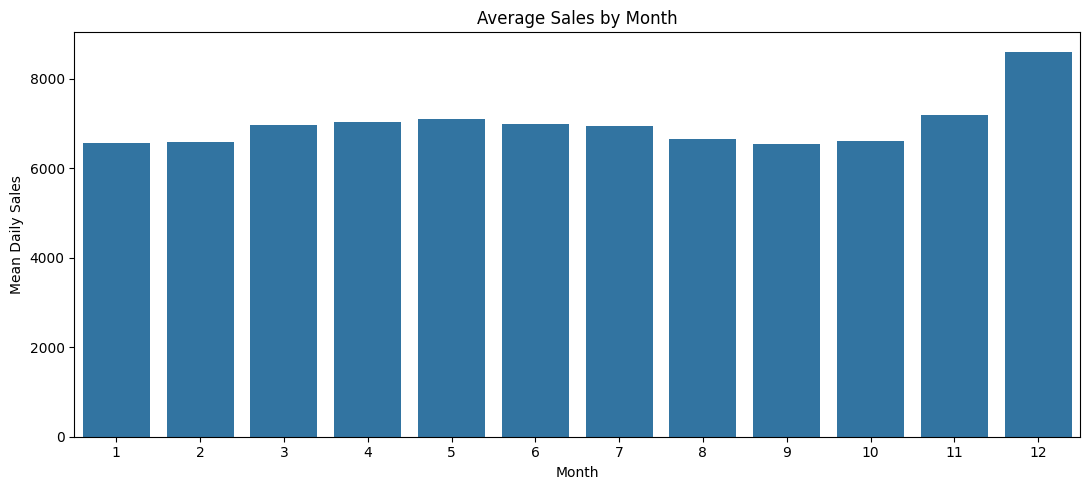

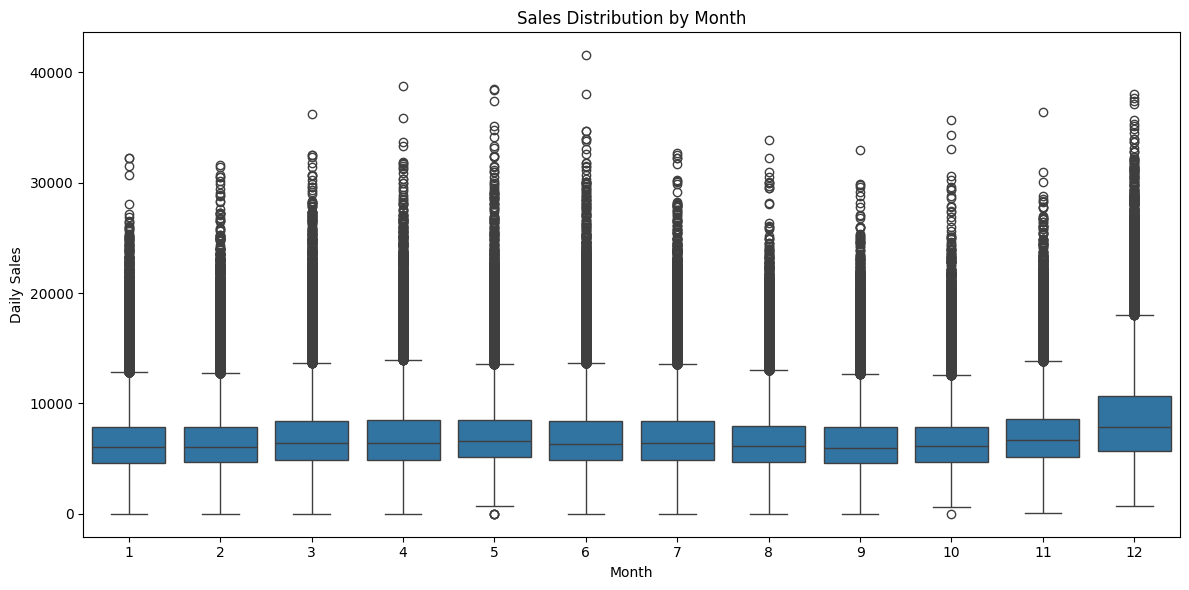

In [17]:
# Bivariate Analysis 8: Sales vs. Month

# Keep open stores with valid Sales and Month
month_df = df[
    (df["Open"] == 1) &
    df["Sales"].notna() &
    df["Month"].notna()
].copy()

# Ensure Month is an integer for correct ordering
month_df["Month"] = month_df["Month"].astype(int)

# Summary statistics by month
month_summary = (
    month_df.groupby("Month")["Sales"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
    .reindex(range(1, 13))
)

print("Sales summary by month (open stores only):")
display(month_summary)

# Average sales by month
plt.figure(figsize=(11, 5))

sns.barplot(
    data=month_df,
    x="Month",
    y="Sales",
    errorbar=None,
    order=list(range(1, 13))
)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Mean Daily Sales")

plt.tight_layout()
plt.show()

# Monthly sales distribution
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=month_df,
    x="Month",
    y="Sales",
    order=list(range(1, 13))
)

plt.title("Sales Distribution by Month")
plt.xlabel("Month")
plt.ylabel("Daily Sales")

plt.tight_layout()
plt.show()

### Relationship Between Month and Sales

The monthly sales analysis reveals variation in daily sales across the calendar year. December records the highest average daily sales of 8,608.96 and the highest median sales of 7,858. September has the lowest average daily sales of 6,546.34.

Sales are relatively stable across much of the year, with increases during May and November and a substantial rise in December. This pattern suggests that seasonal effects may influence customer purchasing behavior and store revenue.

The boxplot also reveals high-sales outliers across all months. These observations should be investigated rather than automatically removed, as they may represent legitimate periods of unusually high demand.

Overall, month appears to be a useful feature for sales forecasting, particularly for capturing seasonal patterns. Further analysis should compare monthly trends across individual years to determine whether the observed pattern is consistent over time.

* Multivariate Analysis

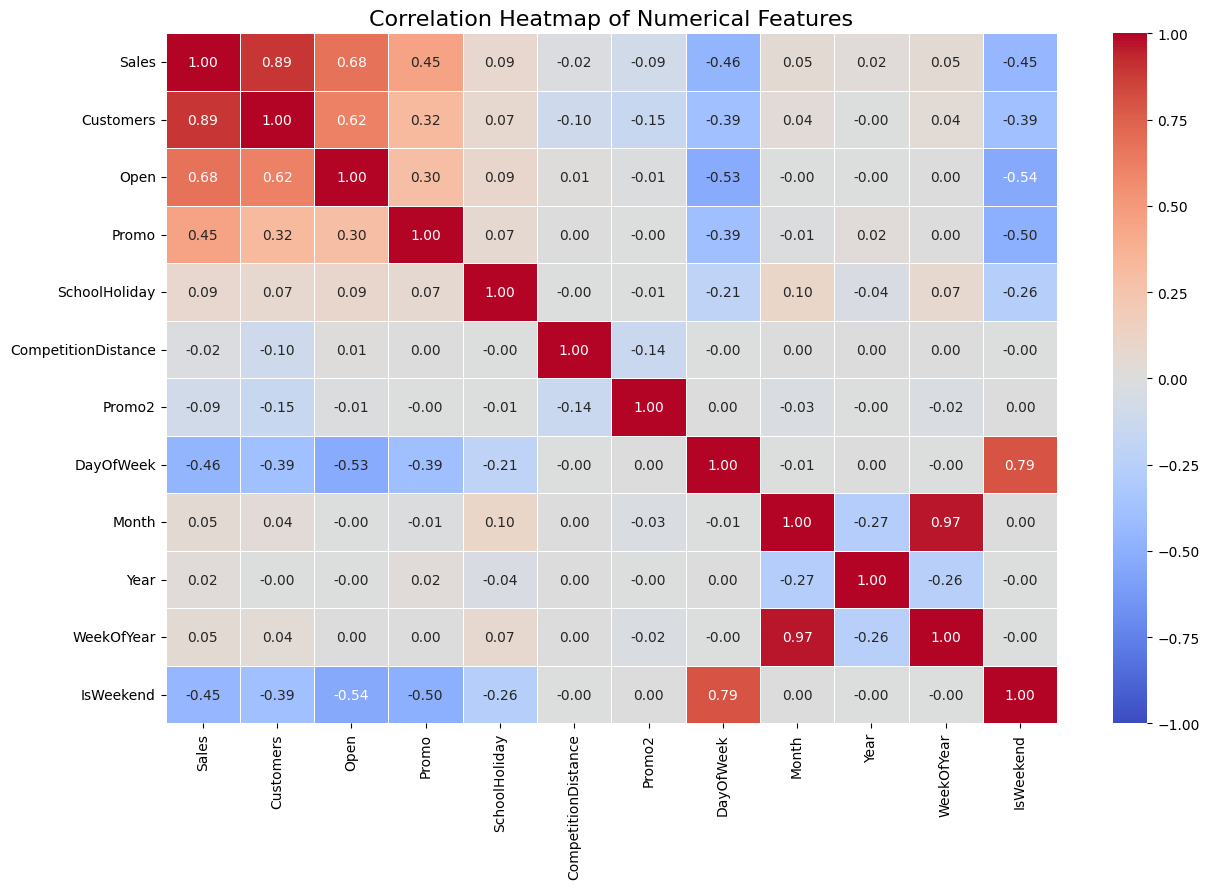

In [18]:
# Select numerical columns relevant to sales analysis
numeric_cols = [
    "Sales",
    "Customers",
    "Open",
    "Promo",
    "SchoolHoliday",
    "CompetitionDistance",
    "Promo2",
    "DayOfWeek",
    "Month",
    "Year",
    "WeekOfYear",
    "IsWeekend"
]

# Keep only columns that exist in the dataset
numeric_cols = [col for col in numeric_cols if col in df.columns]

# Calculate the correlation matrix
corr_matrix = df[numeric_cols].corr()

# Plot the heatmap
plt.figure(figsize=(13, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

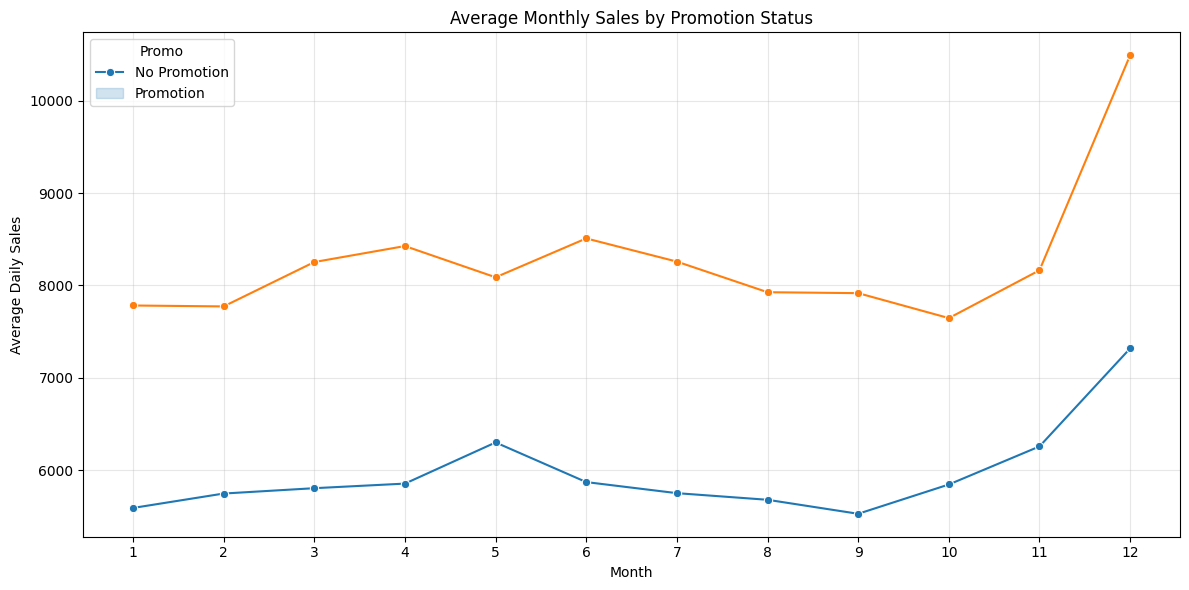

Promo,No Promotion,Promotion
Month,,
1,5591.904236,7782.800277
2,5747.812834,7772.909263
3,5805.723545,8252.983345
4,5855.305439,8426.029528
5,6300.749699,8087.946860
6,5871.747172,8508.684577
7,5751.911514,8257.588809
8,5680.220869,7926.496229
9,5528.634084,7916.399032


In [19]:

# Keep only open stores
open_df = df[df["Open"] == 1].copy()

# Calculate average sales by month and promotion status
monthly_promo_sales = (
    open_df.groupby(["Month", "Promo"])["Sales"]
    .mean()
    .reset_index()
)

# Plot monthly average sales by promotion status
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_promo_sales,
    x="Month",
    y="Sales",
    hue="Promo",
    marker="o"
)

plt.title("Average Monthly Sales by Promotion Status")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")
plt.xticks(range(1, 13))
plt.legend(title="Promo", labels=["No Promotion", "Promotion"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display the numerical results
display(
    monthly_promo_sales.pivot(
        index="Month",
        columns="Promo",
        values="Sales"
    ).rename(columns={0: "No Promotion", 1: "Promotion"})
)


### Relationship Between Monthly Sales and Promotion Status

The multivariate analysis examined average daily sales by month and promotional status, considering only records where stores were open.

The results show that average sales during promotional periods were higher than average sales during non-promotional periods in all twelve months. The largest absolute difference occurred in December, when average sales were 10,490.79 during promotional periods and 7,318.43 during non-promotional periods.

December also recorded the highest average sales for both promotional groups, indicating a seasonal pattern that may be important for sales forecasting. May showed the smallest difference between the two groups.

The findings suggest that both promotion status and monthly seasonality are useful variables to investigate when modeling sales. However, the observed differences are descriptive associations and do not independently establish the causal effect of promotions.

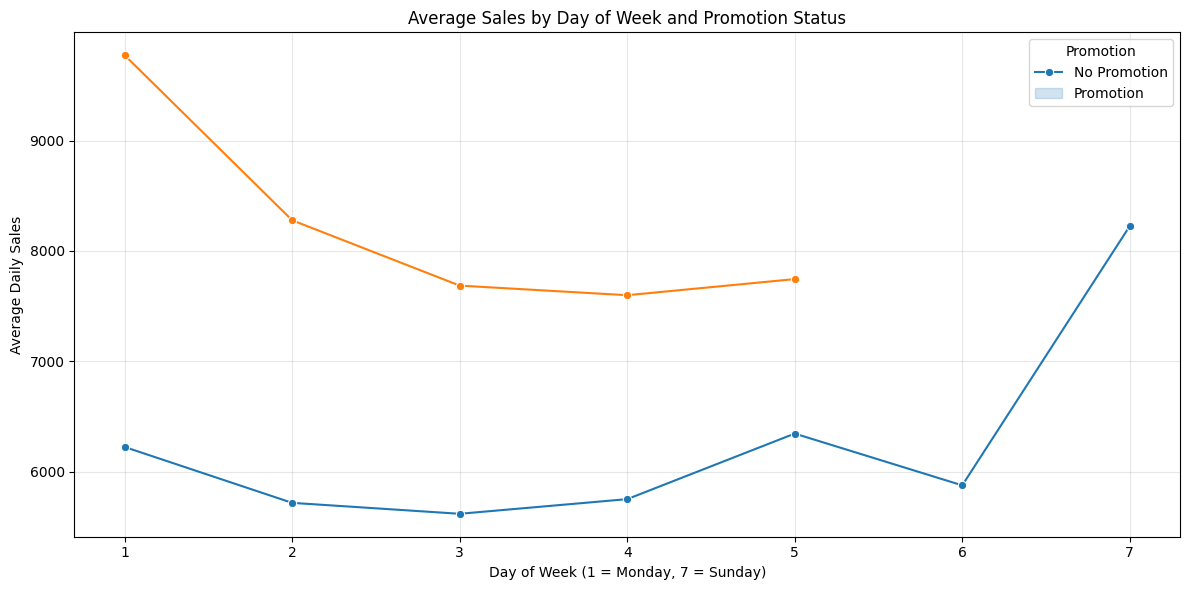

Promo,No Promotion,Promotion
DayOfWeek,,
1,6222.521495,9772.784369
2,5716.241087,8277.201522
3,5617.044778,7685.077816
4,5749.837412,7598.070761
5,6344.030127,7744.066219
6,5874.840238,NaN
7,8224.723908,NaN


In [20]:
# Average sales by weekday and promotion status
weekday_promo_sales = (
    open_df.groupby(["DayOfWeek", "Promo"])["Sales"]
    .mean()
    .reset_index()
)

# Plot the results
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekday_promo_sales,
    x="DayOfWeek",
    y="Sales",
    hue="Promo",
    marker="o"
)

plt.title("Average Sales by Day of Week and Promotion Status")
plt.xlabel("Day of Week (1 = Monday, 7 = Sunday)")
plt.ylabel("Average Daily Sales")
plt.xticks(range(1, 8))
plt.legend(
    title="Promotion",
    labels=["No Promotion", "Promotion"]
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display the results as a table
display(
    weekday_promo_sales.pivot(
        index="DayOfWeek",
        columns="Promo",
        values="Sales"
    ).rename(columns={
        0: "No Promotion",
        1: "Promotion"
    })
)


Promo,No Promotion,Promotion
StoreType,,
a,5808.50,8304.10
b,9566.86,11307.99
c,6028.06,8042.00
d,5855.27,8017.83


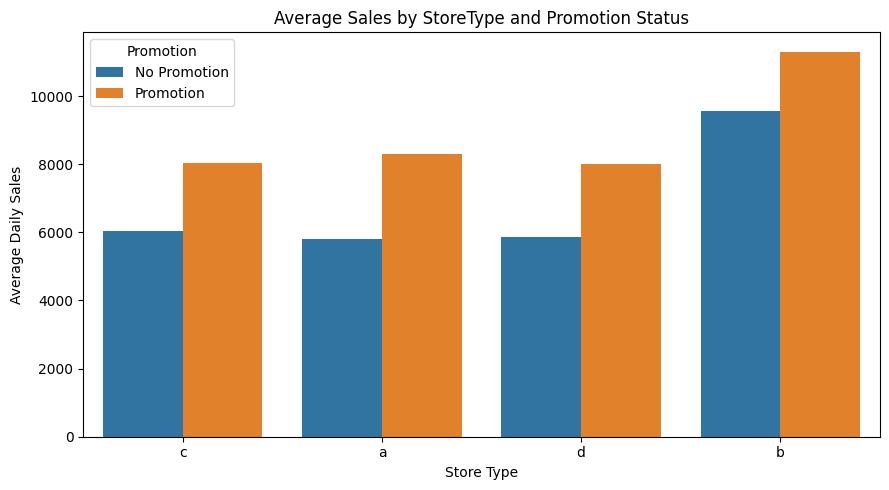

In [21]:

# Calculate average sales by StoreType and Promo
promo_storetype_summary = (
    open_stores.groupby(["StoreType", "Promo"])["Sales"]
    .mean()
    .unstack()
    .rename(columns={0: "No Promotion", 1: "Promotion"})
)

# Display the summary table
display(promo_storetype_summary.round(2))

# Plot average sales
plt.figure(figsize=(9, 5))

sns.barplot(
    data=open_stores,
    x="StoreType",
    y="Sales",
    hue="Promo",
    errorbar=None
)

plt.title("Average Sales by StoreType and Promotion Status")
plt.xlabel("Store Type")
plt.ylabel("Average Daily Sales")
plt.legend(title="Promotion", labels=["No Promotion", "Promotion"])
plt.tight_layout()
plt.show()


### Promotion Impact Across Store Types

The multivariate analysis shows that average daily sales are higher during promotional periods across all four store types. Store Type B records the highest average sales, with approximately 11,308 during promotions and 9,567 without promotions. Store Type A exhibits the largest absolute increase in average sales, approximately 2,496, and the largest relative increase, approximately 42.97%. In comparison, Store Type B shows a smaller relative increase of approximately 18.20%. These findings suggest that the observed relationship between promotions and sales varies across store types. However, these differences represent associations and do not independently establish a causal effect of promotions.

Promo,No Promotion,Promotion
Assortment,,
a,5559.72,7933.45
b,8398.20,9030.07
c,6291.67,8549.35


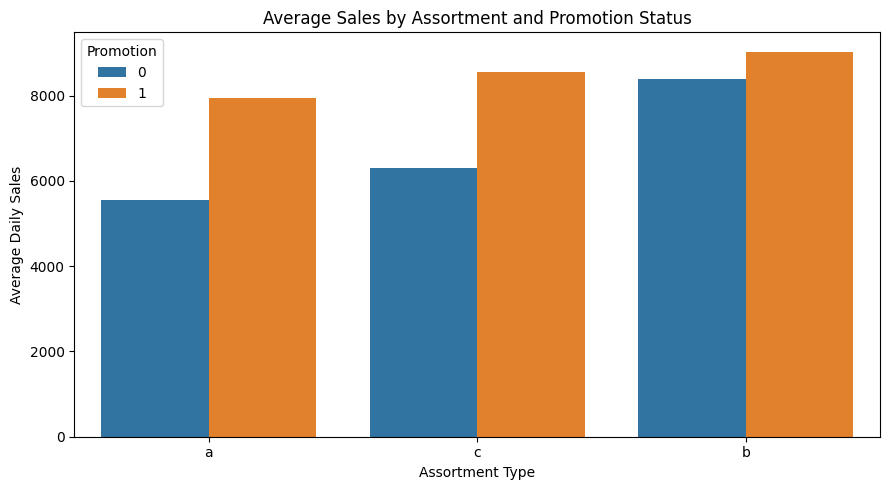

In [22]:
# Calculate average sales by Assortment and Promo
promo_assortment_summary = (
    open_stores.groupby(["Assortment", "Promo"])["Sales"]
    .mean()
    .unstack()
    .rename(columns={0: "No Promotion", 1: "Promotion"})
)

# Display the summary table
display(promo_assortment_summary.round(2))

# Plot average sales
plt.figure(figsize=(9, 5))

sns.barplot(
    data=open_stores,
    x="Assortment",
    y="Sales",
    hue="Promo",
    errorbar=None
)

plt.title("Average Sales by Assortment and Promotion Status")
plt.xlabel("Assortment Type")
plt.ylabel("Average Daily Sales")
plt.legend(title="Promotion")
plt.tight_layout()
plt.show()

### Promotion Impact Across Assortment Types

The analysis indicates that average daily sales are higher during promotional periods across all three assortment types. Assortment B records the highest average sales, with approximately 9,030 during promotions and 8,398 without promotions. However, its relative increase is comparatively small at approximately 7.52%. Assortment A exhibits the largest absolute increase, approximately 2,374, and the largest relative increase, approximately 42.70%. Assortment C also shows a substantial relative increase of approximately 35.88%. These findings suggest that the relationship between promotions and sales varies across assortment types. Since this is descriptive analysis, the observed differences should not be interpreted as proof of causation.

StoreType,a,b,c,d
Month,,,,
1,6540.61,9351.20,6557.07,6447.46
2,6580.15,9938.08,6576.48,6424.92
3,6942.10,10269.39,6961.16,6855.98
4,7031.98,10396.40,6991.76,6898.10
5,7030.85,10669.07,7069.63,7031.12
6,6964.41,10563.20,6840.28,6924.62
7,6930.92,10201.92,6835.58,6850.51
8,6632.40,9528.93,6618.15,6512.24
9,6550.19,9723.50,6471.74,6372.48


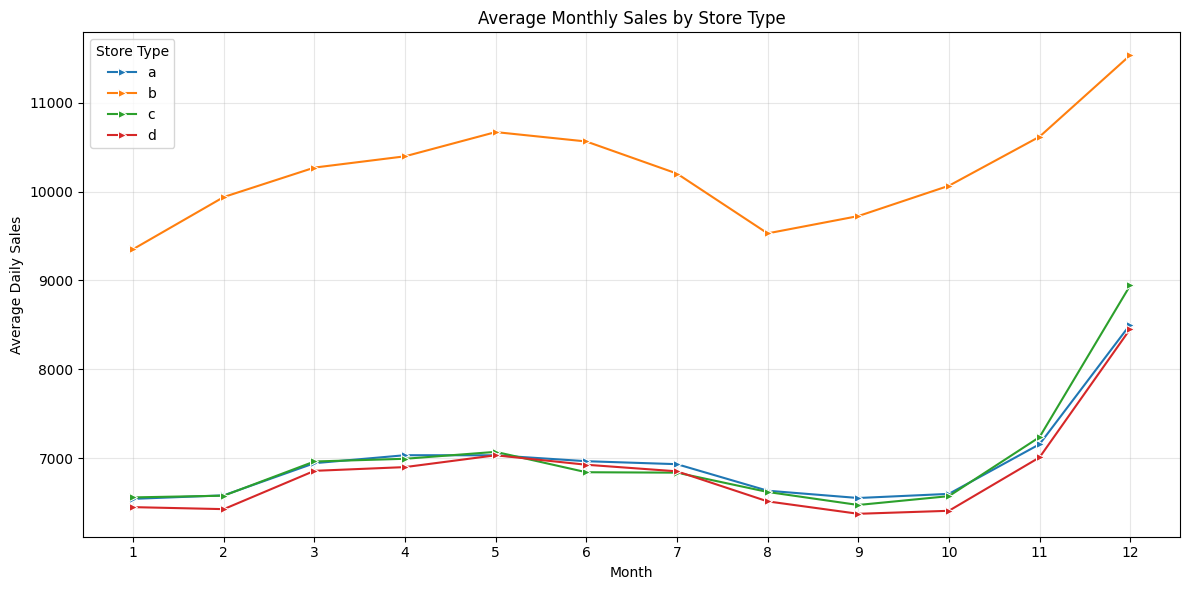

In [23]:

# Calculate average sales by Month and StoreType
monthly_storetype_summary = (
    open_stores.groupby(["Month", "StoreType"])["Sales"]
    .mean()
    .reset_index()
)

# Display summary table
display(
    monthly_storetype_summary.pivot(
        index="Month",
        columns="StoreType",
        values="Sales"
    ).round(2)
)

# Plot monthly trends
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_storetype_summary,
    x="Month",
    y="Sales",
    hue="StoreType",
    marker=">"
)

plt.title("Average Monthly Sales by Store Type")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")
plt.xticks(range(1, 13))
plt.legend(title="Store Type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Monthly Sales Patterns Across Store Types

The analysis reveals clear differences in monthly sales across store types. Store Type B consistently records the highest average monthly sales, reaching approximately 11,534 in December. Store Types A, C, and D exhibit relatively similar patterns, with sales generally declining around August and September before recovering toward the end of the year. December records the highest average sales for all four store types. Among Types A, C, and D, Type C has the highest December average at approximately 8,942. These observations suggest that seasonal patterns and store characteristics may both be relevant when forecasting sales. However, the analysis is descriptive and does not establish the causes of these patterns.

StoreType,a,b,c,d
DayOfWeek,,,,
1,8336.87,11055.02,7988.51,7953.58
2,7294.83,10171.53,6874.86,6661.47
3,6838.06,10013.84,6563.04,6438.63
4,6836.99,10207.54,6599.72,6531.65
5,6998.90,10708.56,6985.37,7050.55
6,5361.15,8011.25,6608.12,6352.56
7,2912.11,11449.91,NaN,3520.27


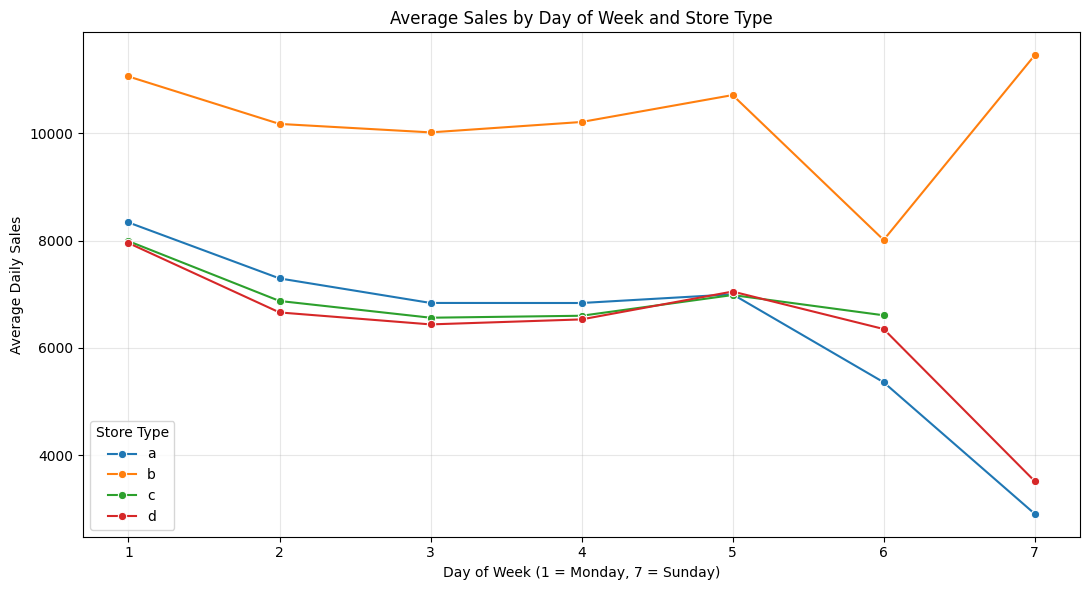

In [24]:

# Calculate average sales by weekday and store type
weekday_storetype_summary = (
    open_stores.groupby(["DayOfWeek", "StoreType"])["Sales"]
    .mean()
    .reset_index()
)

# Display summary table
display(
    weekday_storetype_summary.pivot(
        index="DayOfWeek",
        columns="StoreType",
        values="Sales"
    ).round(2)
)

# Plot weekday sales patterns
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=weekday_storetype_summary,
    x="DayOfWeek",
    y="Sales",
    hue="StoreType",
    marker="o"
)

plt.title("Average Sales by Day of Week and Store Type")
plt.xlabel("Day of Week (1 = Monday, 7 = Sunday)")
plt.ylabel("Average Daily Sales")
plt.xticks(range(1, 8))
plt.legend(title="Store Type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Weekly Sales Patterns Across Store Types

The analysis shows that average daily sales vary by both weekday and store type. Store Type B records the highest average sales on every day represented in the results, reaching approximately 11,450 on Sunday and 11,055 on Monday. For Store Types A, C, and D, Monday is the strongest weekday, while sales generally decline toward Wednesday before recovering on Friday. Saturday sales are comparatively low, particularly for Store Type A. Sunday results require caution because store-opening patterns differ, and Store Type C has no qualifying open-store observations for that day. These findings indicate that weekday effects and store characteristics are useful factors to investigate in sales forecasting.

# Final Exploratory Data Analysis (EDA) Summary

## 1. Univariate Analysis

- **Sales:** Daily sales are right-skewed, with a mean of approximately 5,774 and a median of 5,744. A substantial number of records have zero sales, primarily reflecting store closures.
- **Customers:** Customer counts are right-skewed, with a mean of approximately 633 and a median of 609. There are 172,869 records with zero customers.
- **Competition Distance:** The distribution is strongly right-skewed, with a median distance of 2,330 and a maximum of 75,860.
- **Store Type:** Type A accounts for the largest share of daily records, followed by Types D, C, and B.
- **Assortment:** Types A and C account for most daily records, while Type B is comparatively rare.
- **Promotions:** Approximately 38.15% of training records have Promo = 1.
- **Promo2:** Approximately half of the training records have Promo2 = 1.
- **Holidays:** Most records have no state holiday or school holiday.

## 2. Bivariate Analysis

- **Sales and Customers:** Sales and customer counts have a strong positive correlation. The correlation is approximately 0.8236 when considering open stores only.
- **Promotion and Sales:** Average sales are approximately 8,228 on promotion days and 5,929 on non-promotion days for open stores.
- **Day of Week:** Average sales vary by weekday, with Monday showing high average sales and Saturday showing lower average sales.
- **Store Type:** Store Type B has the highest average sales among the four store types.
- **Assortment:** Assortment Type B has the highest average sales among the assortment categories.
- **School Holidays:** Average sales are slightly higher during school holidays than outside school holidays.
- **Monthly Trends:** December has the highest average monthly sales, suggesting a seasonal pattern.

## 3. Multivariate Analysis

- **Promotion × Store Type:** Average sales are higher during promotions across all four store types. Type A has the largest relative increase based on the observed averages.
- **Promotion × Assortment:** Average sales are higher during promotions across all three assortment types. Assortment A has the largest relative increase.
- **Month × Store Type:** All four store types show a substantial increase in average sales in December. Type B consistently records the highest monthly averages.
- **Day of Week × Store Type:** Weekly sales patterns differ by store type. Type B has the highest observed average sales across the weekdays and Sunday, although Sunday results should be interpreted cautiously because opening patterns vary.

## 4. Overall Conclusions

The EDA identifies several potentially useful predictors of Rossmann store sales, including promotions, customer counts, day of week, month, store type, assortment, and holiday indicators.

Promotions are associated with higher average sales, while store types differ considerably in their typical sales levels. Monthly and weekly patterns also suggest that temporal features are important for forecasting.

These findings are descriptive and do not independently establish causal relationships. Customer counts are strongly associated with sales, but the Customers column is not available in the test dataset and should not be used as an input when predicting test sales.

In [26]:
logger.info("Univariate analysis completed.")
logger.info("Bivariate analysis completed.")
logger.info("Multivariate analysis completed.")
logger.info("EDA findings summarized.")
logger.info("Rossmann Store Sales EDA completed successfully.")

print("EDA completion recorded successfully!")

EDA completion recorded successfully!


In [27]:
from google.colab import files

files.download("logs/rossmann_eda.log")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>